In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F
from IPython.display import clear_output
from pdm_model import Net, SimpleNet
warnings.filterwarnings("ignore")
clear_output()

In [2]:
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation
kwargs = {'dt': dt, 'dim_ring': dim_ring}
seq_len = 100
tasks = get_collection('yang19')
envs = [ngym.make(task, **kwargs) for task in tasks]
schedule = RandomSchedule(len(envs))
env = ScheduleEnvs(envs, schedule=schedule, env_input=True)
seq_len = 100
batch_size = 32
dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)
env = dataset.env
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n
device = 'cuda'
hidden_size = 64

In [3]:
net = Net(ob_size=ob_size, num_h=hidden_size, act_size=act_size, entropy_loss=True).to(device)
simple_net = SimpleNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size).to(device)

In [4]:
net.load_state_dict(torch.load('./model/multitask/yang19_ei_softplus.pth', map_location=device))
simple_net.load_state_dict(torch.load('./model/multitask/yang19_simple_softplus.pth', map_location=device))

<All keys matched successfully>

In [5]:
from pdm_train import train
epochs = 2000
lyapunov_every = 1000
learning_rate = 0.01
weight_decay = 1e-5
rate_l1 = 0.0
weight_l1 = 0.0
kwargs = {'epochs': epochs, 'lyapunov_every': lyapunov_every, 'device': device,
          'batch_size': batch_size, 'seq_len': seq_len, 'env': env,
          'lr': learning_rate, 'weight_decay': weight_decay, 'rate_l1': rate_l1,
          'weight_l1': weight_l1}
net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(net=net, **kwargs)
simple_net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(net=simple_net, **kwargs)

Epoch [0/2000], Loss: 2.6424
Epoch [1000/2000], Loss: 0.0655
Finished Training
Epoch [0/2000], Loss: 1.5181
Epoch [1000/2000], Loss: 0.0464
Finished Training


Evaluating model performance across 100 trials...

Average performance across all environments:
yang19.go-v0: 1.0000
yang19.rtgo-v0: 1.0000
yang19.dlygo-v0: 1.0000
yang19.anti-v0: 1.0000
yang19.rtanti-v0: 1.0000
yang19.dlyanti-v0: 1.0000
yang19.dm1-v0: 0.9500
yang19.dm2-v0: 0.9500
yang19.ctxdm1-v0: 0.9400
yang19.ctxdm2-v0: 0.9600
yang19.multidm-v0: 0.9200
yang19.dlydm1-v0: 0.9900
yang19.dlydm2-v0: 1.0000
yang19.ctxdlydm1-v0: 1.0000
yang19.ctxdlydm2-v0: 0.9900
yang19.multidlydm-v0: 0.9000
yang19.dms-v0: 1.0000
yang19.dnms-v0: 1.0000
yang19.dmc-v0: 1.0000
yang19.dnmc-v0: 1.0000
Evaluating model performance across 100 trials...

Average performance across all environments:
yang19.go-v0: 1.0000
yang19.rtgo-v0: 1.0000
yang19.dlygo-v0: 1.0000
yang19.anti-v0: 1.0000
yang19.rtanti-v0: 1.0000
yang19.dlyanti-v0: 1.0000
yang19.dm1-v0: 0.8400
yang19.dm2-v0: 0.9200
yang19.ctxdm1-v0: 0.6300
yang19.ctxdm2-v0: 0.6600
yang19.multidm-v0: 0.9400
yang19.dlydm1-v0: 0.9800
yang19.dlydm2-v0: 0.9800
yang19.ct

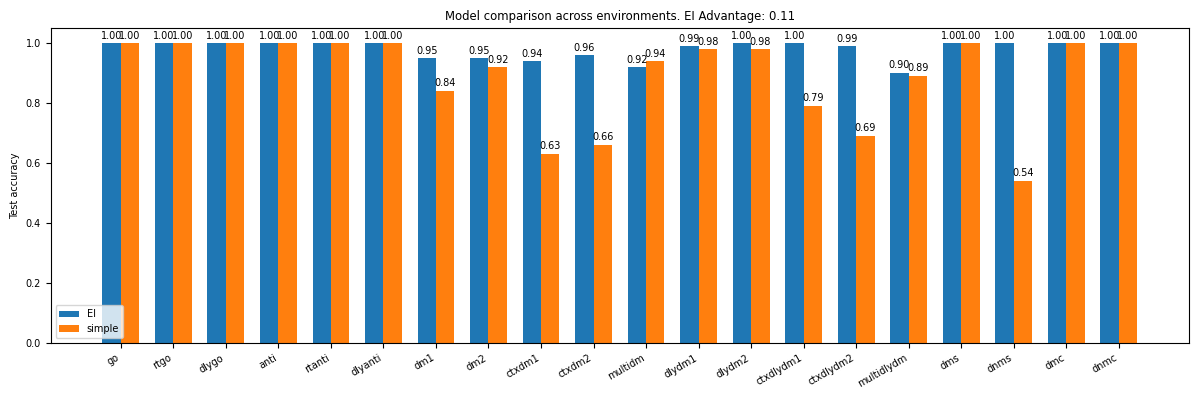

In [5]:
from pdm_train import test_multitask, plot_test_performance
mean_acc = test_multitask(env, net, eval_trials=EVAL_TRIALS, device=device)
mean_acc_simple = test_multitask(env, simple_net, eval_trials=EVAL_TRIALS, device=device)
relative_advantage = (mean_acc - mean_acc_simple) / (mean_acc + mean_acc_simple + 1e-6) * 2
print(f"Relative advantage of EI over simple model: {relative_advantage.mean():.3f}")
env_names = [e_i.spec.id for e_i in env.envs]
env_names = [x.split('yang19.')[1].split('-v0')[0] for x in env_names]
plot_test_performance(mean_acc, mean_acc_simple, env_names, show_values=True)

In [6]:
def task_variance_hidden_dict(net):
    EVAL_TRIALS = 300
    hidden_size = net.hidden_size
    hidden_dict = {}
    for e_i in env.envs:
        hidden_dict[e_i.spec.id] = dict()
    for env_idx, e_i in enumerate(env.envs):
        e_i.sigma = 0
        period_keys = list(e_i.start_ind.keys())
        trial_length = max(list(e_i.end_ind.values()))
        hidden_ar = np.zeros((2, EVAL_TRIALS, len(period_keys), hidden_size))
        for trial_idx in range(EVAL_TRIALS):
            trial = e_i.new_trial()
            ob, gt = e_i.ob, e_i.gt
            trial_length = ob.shape[0]

            # Add one-hot encoding for the environment
            env_one_hot = np.zeros((trial_length, len(env.envs)))
            env_one_hot[:, env_idx] = 1.0  # Set the current environment index to 1

            # Concatenate original observation with one-hot encoding
            ob_with_env = np.concatenate([ob, env_one_hot], axis=1)

            ob_with_env = ob_with_env[:, np.newaxis, :]  # Add batch dimension
            inputs = torch.from_numpy(ob_with_env).float().to(device)
            with torch.no_grad():
                outputs, _, hidden = net(inputs)
            # hidden = sl_model.init_hidden(1, device)
            hidden = hidden[0].squeeze(1)  # Remove batch dimension
            # if np.isnan(hidden.detach().cpu().numpy()).any():
            #     print(f"NaN detected in hidden state for environment {e_i.spec.id}, trial {trial_idx}")
            #     raise ValueError("NaN detected in hidden state")
            for i, k in enumerate(period_keys):
                start_ind = e_i.start_ind[k]
                end_ind = e_i.end_ind[k]
                hidden_slice = hidden[start_ind:end_ind, :]
                # average = hidden_slice.mean(dim=0).detach().cpu().numpy()
                # variance = hidden_slice.var(dim=0).detach().cpu().numpy()
                # if np.isnan(average).any() or np.isnan(variance).any():
                #     print(f"NaN detected in hidden state for environment {e_i.spec.id}, trial {trial_idx}, period {k}")
                #     print("start_ind:", start_ind, "end_ind:", end_ind)
                #     print(f"Hidden state:", hidden_slice)
                #     raise ValueError("NaN detected in hidden state")
                hidden_ar[0, trial_idx, i, :] = hidden_slice.mean(dim=0).detach().cpu().numpy()
                hidden_ar[1, trial_idx, i, :] = hidden_slice.var(dim=0).detach().cpu().numpy()


        for i, k in enumerate(period_keys):
            period_mean = hidden_ar[0, :, i, :].mean(axis=0)
            # period_var = hidden_ar[1, :, i, :].mean(axis=0) + hidden_ar[0, :, i, :].var(axis=0)
            # period_var = hidden_ar[0, :, i, :].std(axis=0)
            period_var = hidden_ar[1, :, i, :].mean(axis=0)
            hidden_dict[e_i.spec.id][k] = np.stack([period_mean, period_var],0)
    return hidden_dict

def normalize_variance(hidden_dict):
    titles = []
    data = []
    for k, v in hidden_dict.items():
        env_name = k.split('.')[1].split('-')[0]
        for k2, v2 in v.items():
            if 'fixation' in k2.lower():
                continue
            if not np.isnan(v2[1]).any():
                titles.append(f"{env_name} {k2}")
                data.append(v2[1])
    data = np.array(data)
    data_normalized = (data - np.nanmin(data, axis=0))/(np.nanmax(data, axis=0) - np.nanmin(data, axis=0))
    data_normalized = np.where(np.isnan(data_normalized), 0, data_normalized)
    return {'titles': titles, 'variance': data_normalized}

In [17]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from scipy.cluster.hierarchy import dendrogram
from scipy.cluster.hierarchy import leaves_list
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import silhouette_score

def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)
    order = leaves_list(linkage_matrix)
    return order

def best_silhouette_hierarchical(
    X,
    min_k=2,
    max_k=40,
    linkage_method="ward",
    metric="euclidean",
    random_state=None,
):
    """
    扫描 dendrogram 的距离阈值，计算 silhouette，返回最佳阈值与簇数。
    - linkage_method: 'ward' | 'average' | 'complete' | 'single' | ...
      * 若用 'ward'，请配合欧氏距离（metric='euclidean'）。
    - metric: 计算样本间距离的度量，传给 pdist。
    """
    rng = np.random.default_rng(random_state)

    # 1) 预先计算成对距离（一次性），并转为方阵供 silhouette 复用
    #    注意：若后面用 silhouette_score(..., metric="precomputed"),
    #    需要对角线为 0。scikit-learn 文档亦有说明。
    #    （我们用 squareform 自动满足对角线为 0 的要求）
    d_condensed = pdist(X, metric=metric)                 # shape: (n*(n-1)/2,)
    D = squareform(d_condensed)                           # shape: (n, n)

    # 2) 生成层次聚类的 linkage 矩阵（以距离为输入）
    #    linkage 的输入若是 condensed 距离向量，则不要再传 metric。
    Z = linkage(d_condensed, method=linkage_method)       # Z[:,2] 是各次合并的距离

    # 3) 以 dendrogram 的“合并高度”（距离）作为候选阈值
    heights = np.unique(Z[:, 2])
    # 为了在相邻高度之间也能切割，取相邻高度中点作为候选阈值（再加上边界）
    mids = (heights[:-1] + heights[1:]) / 2.0
    # 候选阈值集合：包含所有中点 + 略小于最小高度、略大于最大高度的两个保护值
    eps = 1e-12
    candidates = np.concatenate(([heights[0] - eps], mids, [heights[-1] + eps]))

    best_overall = {
        "k": None,
        "threshold": None,
        "score": -np.inf,
        "labels": None,
    }
    # 记录每个 k 的最佳（便于画图或复查）
    best_per_k = {}  # k -> (score, threshold, labels)

    for t in candidates:
        labels = fcluster(Z, t=t, criterion="distance")   # 以距离阈值切树得到簇标签
        k = len(np.unique(labels))
        if k < min_k or k > max_k or k < 2:
            continue
        # silhouette：按定义=每点 (d_inter - d_intra)/max(d_intra, d_inter)，再取均值
        # 这里直接用 sklearn 的实现，传入预计算的距离矩阵
        score = silhouette_score(D, labels, metric="precomputed")

        # 更新 per-k 的最好
        prev = best_per_k.get(k, (-np.inf, None, None))
        if score > prev[0]:
            best_per_k[k] = (score, t, labels.copy())

        # 更新 overall 最好
        if score > best_overall["score"]:
            best_overall.update(dict(k=k, threshold=t, score=score, labels=labels.copy()))

    return best_overall, best_per_k

def best_kmeans_score(X, min_k=2, max_k=40, random_state=0):
    """
    扫描 K-Means 的簇数，计算 silhouette，返回最佳簇数与阈值。
    """
    best_overall = {
        "k": None,
        "score": -np.inf,
        "labels": None,
    }
    best_per_k = {}  # k -> (score, labels)

    for k in range(min_k, max_k + 1):
        kmeans = KMeans(n_clusters=k, random_state=random_state)
        labels = kmeans.fit_predict(X)
        score = silhouette_score(X, labels)

        # 更新 per-k 的最好
        prev = best_per_k.get(k, (-np.inf, None))
        if score > prev[0]:
            best_per_k[k] = (score, labels.copy())

        # 更新 overall 最好
        if score > best_overall["score"]:
            best_overall.update(dict(k=k, score=score, labels=labels.copy()))

    return best_overall, best_per_k

def plot_task_variance_matrix(variance_info):
    X = variance_info['variance']
    best_overall, best_per_k = best_silhouette_hierarchical(X)
    best_threshold_row = best_overall["threshold"]
    best_score_row = best_overall["score"]
    best_overall, best_per_k = best_silhouette_hierarchical(X.T)
    best_threshold_col = best_overall["threshold"]
    best_score_col = best_overall["score"]
    best_overall_kmeans, best_per_kmeans = best_kmeans_score(X)
    best_k_row_kmeans = best_overall_kmeans["k"]
    best_score_row_kmeans = best_overall_kmeans["score"]
    best_overall_kmeans, best_per_kmeans = best_kmeans_score(X.T)
    best_k_col_kmeans = best_overall_kmeans["k"]
    best_score_col_kmeans = best_overall_kmeans["score"]


    # ==== 1) 计算层次聚类的 linkage 矩阵 ====
    Z_row = linkage(pdist(X,  metric='euclidean'), method='ward')
    Z_col = linkage(pdist(X.T, metric='euclidean'), method='ward')

    # ==== 2) 根据叶序重排 ====
    row_order = leaves_list(Z_row)  # 行从上到下顺序
    col_order = leaves_list(Z_col)  # 列从左到右顺序
    X_ord = X[row_order][:, col_order]  # 先行后列重排

    # ==== 3) 手工布局 ====
    # fig = plt.figure(figsize=(8, 12))

    # ======= 2) 手工布局参数（全部是相对figure的比例） =======
    left_margin   = 0.08
    right_margin  = 0.06
    top_margin    = 0.06
    bottom_margin = 0.10

    w_row_dend = 0.1   # 右侧行树宽度
    h_col_dend = 0.1   # 顶部列树高度
    pad        = 0.005   # 树与热图的间距

    cbar_h     = 0.03   # 底部色条高度
    cbar_pad   = 0.01   # 色条与热图的间距

    # ======= 3) 由参数计算各区域位置 =======
    fig = plt.figure(figsize=(8, 10))

    # 让热图底部留出色条空间
    heat_left   = left_margin
    heat_bottom = bottom_margin + cbar_h + cbar_pad
    heat_width  = 1 - (left_margin + w_row_dend + pad + right_margin)
    heat_height = 1 - (heat_bottom + h_col_dend + pad + top_margin)

    # 轴：热图、列树(上)、行树(右)、色条(下)
    ax_heat = fig.add_axes([heat_left, heat_bottom, heat_width, heat_height])

    ax_col  = fig.add_axes([heat_left,
                            heat_bottom + heat_height + pad,
                            heat_width, h_col_dend])

    ax_row  = fig.add_axes([heat_left + heat_width + pad,
                            heat_bottom,
                            w_row_dend, heat_height])

    ax_cbar = fig.add_axes([heat_left,
                            bottom_margin,
                            heat_width, cbar_h])

    # ======= 4) 画列树（上）与行树（右） =======
    title_fontsize = 15
    dendrogram(Z_col, ax=ax_col, orientation='top',  no_labels=True, color_threshold=best_threshold_col)
    ax_col.set_xticks([]); ax_col.set_yticks([])
    ax_col.spines[['top','right','bottom','left']].set_visible(False)
    ax_col.set_title((f'Hidden units. Best threshold: {best_threshold_col:.3f}, score: {best_score_col:.3f}. '
                     f'Best K: {best_k_col_kmeans}, score: {best_score_col_kmeans:.3f}'), fontsize=title_fontsize)

    # 注意：行树在右侧，用 orientation='right'，叶子会在轴的左侧，贴近热图
    dendrogram(Z_row, ax=ax_row, orientation='right', no_labels=True, color_threshold=best_threshold_row)
    ax_row.set_xticks([]); ax_row.set_yticks([])
    # ax_row.axis('off')  # 不显示行树的轴
    ax_row.spines[['top','right','bottom','left']].set_visible(False)
    ax_row.set_ylabel((f"Task periods. Best threshold: {best_threshold_row:.3f}, score: {best_score_row:.3f}. "
                        f"Best K: {best_k_row_kmeans}, score: {best_score_row_kmeans:.3f}"),
                    rotation=270, labelpad=12, loc="center", fontsize=title_fontsize)
    ax_row.yaxis.set_label_position("right")

    # ======= 5) 画热图并加底部色条（横向） =======
    im = ax_heat.imshow(X_ord, aspect='auto', interpolation='nearest', cmap='viridis')
    ax_heat.set_xticks([])
    ax_heat.set_yticks(np.arange(len(variance_info['titles'])))
    ax_heat.set_yticklabels(np.array(variance_info['titles'])[row_order])

    cb = fig.colorbar(im, cax=ax_cbar, orientation='horizontal')

    plt.savefig('./output/multitask/yang19_clustering.png', bbox_inches='tight')
    plt.show()
    return row_order, col_order

In [8]:
hidden_dict = task_variance_hidden_dict(net)

In [9]:
variance_info = normalize_variance(hidden_dict)

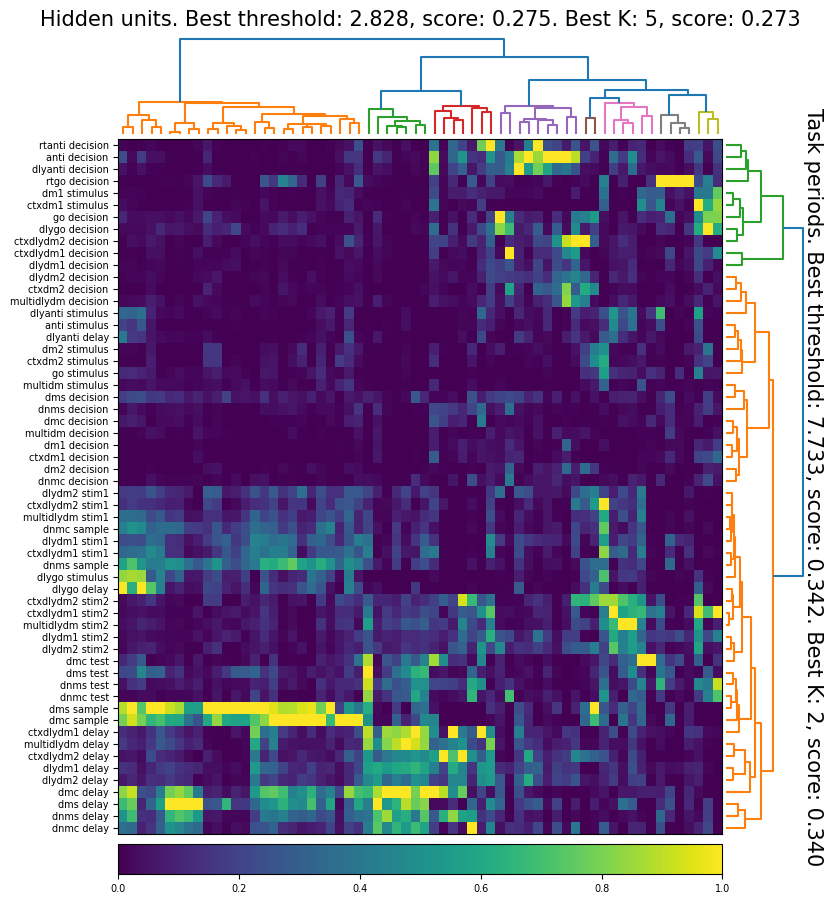

In [18]:
row_order, col_order = plot_task_variance_matrix(variance_info)

In [11]:
hidden_dict_simple = task_variance_hidden_dict(simple_net)

In [12]:
variance_info_simple = normalize_variance(hidden_dict_simple)

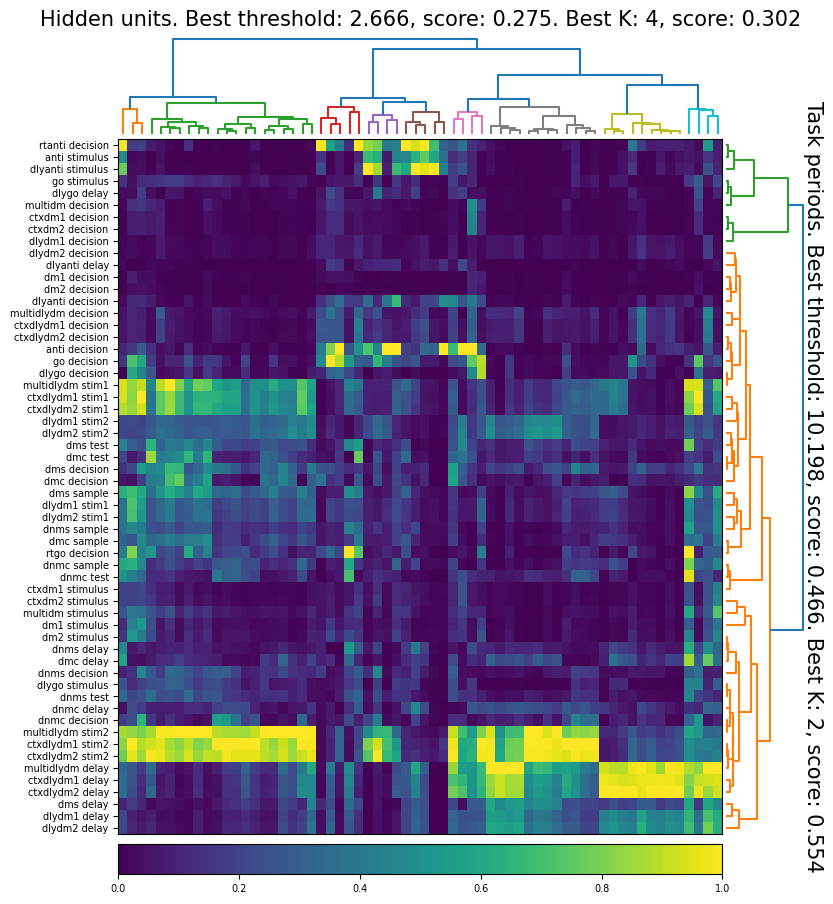

In [19]:
row_order_simple, col_order_simple = plot_task_variance_matrix(variance_info_simple)

In [ ]:
import pickle as pkl
variance_info['row_order'] = row_order
variance_info['col_order'] = col_order
variance_info_simple['row_order'] = row_order_simple
variance_info_simple['col_order'] = col_order_simple
# with open('./output/multitask/yang19_variance.pkl', 'wb') as f:
#     pkl.dump(variance_info, f)
# with open('./output/multitask/yang19_variance_simple.pkl', 'wb') as f:
#     pkl.dump(variance_info_simple, f)